# Numerical Optimization of gut-immune interactions

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.interpolate import interp1d
from math import erf
import numba as nb
import multiprocessing as mp
from tqdm import tqdm
from joblib import Parallel, delayed
import os
from sklearn.feature_selection import mutual_info_classif
import time

plt.style.use('/Users/ObinnaUkogu/Desktop/custom.mplstyle')
%config InlineBackend.figure_format = 'retina'

### A. Define model parameters and useful functions

In [2]:
# Define model parameters
nr, ng, nb = 20, 50, 20 # (receptors, microbes, resources)

F = np.random.uniform(size=(ng,nr)) # cross-reactivity: F_i,r = f_r,i
A = np.random.uniform(low = -0.1, high = 0.1, size = (ng,ng)) # species competition matrix
A[np.arange(0,ng),np.arange(0,ng)] = -1

b = np.random.uniform(size = nb) # resource abundance
C = 5*np.random.uniform(size=(ng,nb)) # resource utilization matrix
D0 = np.random.uniform(size=(nb,ng)) # resource benefit matrix
mu = np.random.uniform(size = ng) # rates of breaching gut epithelium

gam_min, gam_max = 0,1

P0 = np.random.dirichlet(np.ones(nr))
gam0 = 0.9

beta = 0.0 # scaling of microbe benefit

In [31]:
# Define functions
Lam = 25 # strength of immune pressure

def h(gam):
    return gam

def lam(P, gam):
    return Lam*h(gam)*F.dot(P)

# Define parameters

# Define cost function
def g_ss(P,gam):
    return np.maximum(np.linalg.solve(A, lam(P, gam) - C.dot(b)),0)

def B(P,gam):
    return b.T.dot(D0.dot(g_ss(P,gam)))

def objective(pg):
    P, gam = pg[:-1], pg[-1]
    
    cost = (1-h(gam)*F.dot(P)).T.dot(g_ss(P,gam)*mu) - beta*B(P,gam)
    grad_P = (-gam*np.diag(mu).dot(F)).T.dot(np.linalg.solve(A, Lam*gam*F.dot(P)-C.dot(b))) \
            + (Lam*gam*F).T.dot(np.linalg.solve(A.T, mu - gam*np.diag(mu).dot(F.dot(P)) - beta*b.T.dot(D0)))
    grad_gam = (-np.diag(mu).dot(F.dot(P))).T.dot(np.linalg.solve(A, Lam*gam*F.dot(P)-C.dot(b))) \
            + (Lam*F.dot(P)).T.dot(np.linalg.solve(A.T, mu - gam*np.diag(mu).dot(F.dot(P)) - beta*b.T.dot(D0)))
    
    return cost, np.append(grad_P,grad_gam)

### B. Simulate microbe-immune dynamics

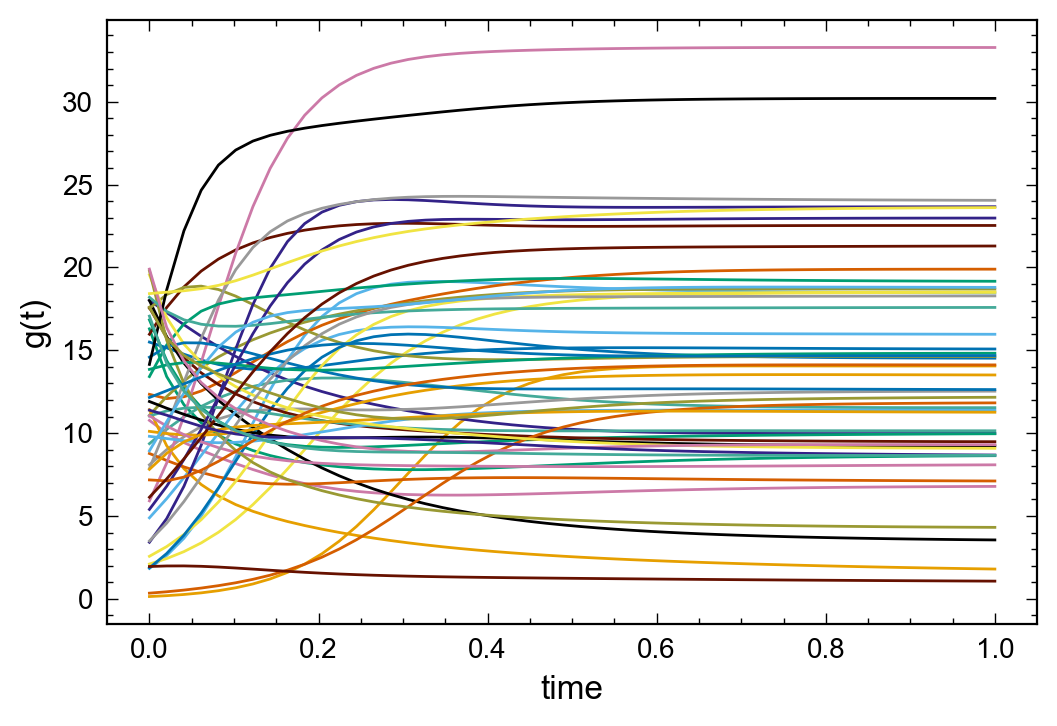

In [32]:
# Simulate microbe dynamics
from scipy.integrate import odeint

# function that returns dx/dt = A x 
def model(g,t):
    dgdt = (-lam(P0,gam0) + C.dot(b) + A.dot(g)).dot(np.diag(g))
    return list(dgdt.ravel())

# initial condition
g0 = 20*np.random.rand(ng)

# time points
t = np.linspace(0,1)

# solve ODE
g = odeint(model,list(g0),t)

# plot results
plt.plot(t,g)
plt.xlabel('time')
plt.ylabel('g(t)')
plt.show()

In [34]:
# Sanity checks
objective(np.append(P0,gam0))
#B(P0,gam0)
np.abs(g[-1] - g_ss(P0,gam0))/g[-1]

array([1.42117979e-03, 3.02103703e-03, 9.48343707e-03, 2.37655793e-03,
       6.40446175e-03, 3.02923737e-03, 3.01683404e-03, 1.17219913e-03,
       2.44196895e-04, 2.12984444e-03, 2.53601453e-03, 2.84794150e-03,
       2.15363412e-02, 2.07738890e-03, 2.48383716e-01, 8.92060199e-03,
       7.40657370e-03, 2.32455436e-04, 2.42479238e-03, 2.37512440e-04,
       1.04849309e-04, 4.08438868e-03, 1.19741184e-03, 1.53850736e-04,
       1.72490228e-03, 1.65118848e-04, 1.67108201e-04, 6.33002967e-03,
       2.41883430e-03, 3.09195399e-03, 1.09025987e-02, 5.46125465e-03,
       4.85675596e-03, 8.84466825e-03, 1.65092113e-01, 4.26532629e-04,
       2.23101272e-03, 2.37795933e-03, 3.78229271e-04, 1.03612180e-03,
       2.61442616e-03, 1.00737199e-03, 1.39026705e-03, 7.32687403e-03,
       2.09286236e-03, 8.92453579e-04, 7.98093404e-03, 3.43931006e-03,
       1.27066703e-02, 4.88809309e-03])

### C. Find optimal repertoire and tolerance level

In [35]:
# Implement proximal gradient optimization for repertoire: https://pypi.org/project/pyproximal/
def project(pg, mask=None):
    """ Take a vector pg (with possible nonnegative entries and non-normalized)
        and project it onto the unit simplex. Take value gamma and project it onto an interval
        mask:   do not project these entries
                project remaining entries onto lower dimensional simplex
    """
    x, z = pg[:-1], pg[-1]
    
    if mask is not None:
        mask = np.asarray(mask)
        xsorted = np.sort(x[~mask])[::-1]
        # remaining entries need to sum up to 1 - sum x[mask]
        sum_ = 1.0 - np.sum(x[mask])
    else:
        xsorted = np.sort(x)[::-1]
        # entries need to sum up to 1 (unit simplex)
        sum_ = 1.0
    lambda_a = (np.cumsum(xsorted) - sum_) / np.arange(1.0, len(xsorted)+1.0)
    for i in np.arange(len(lambda_a)-1):
        if lambda_a[i] >= xsorted[i+1]:
            astar = i
            break
    else:
        astar = -1
    p = np.maximum(x-lambda_a[astar],  0)
    if mask is not None:
        p[mask] = x[mask]
    # project gam
    g = np.maximum(gam_min, np.minimum(z, gam_max))
    
    return np.append(p, g)

def minimize(objective, pg0,
             nboundupdate=100,
             reltol=1e-4, abstol=0.0, maxiters=1e7,
             algo='fast',
             show_progress=False,
             callback=None,
             full_return=False,
             mask=None):
    """
    minimize     objective(P_r)
    subject to   0.0 <= P_r
                 sum(P_r) = 1
    parameters
    ----------
    objective : function returning cost, gradient
    pg0 : starting guess for receptor Pr and tolerance gam
    nboundupdate : number of iteration between lower bound updates
    reltol, abstol, maxiters: numerical parameter
    algo: fast or normal algorithm
    show_progress: print status information during the run
    full_return: also return dict with information about optimization
    mask: Boolean array with directions along which not to optimize
    output
    ------
    optimal solution
    """

    if mask is not None:
        mask = np.asarray(mask)

        def mobjective(x):
            f, grad = objective(x)
            if grad is not None:
                grad[mask] = 0.0
            return f, grad
        mobjective = mobjective
        mproject = lambda pg: project(pg, mask)
    else:
        mobjective = objective
        mproject = project
    # initialize p and g from function input
    pg = mproject(np.asarray(pg0))
    # counting variable for number of iterations
    k = 0
    # lower bound for the cost function
    low = -beta*B(pg[:-1],pg[-1]) #0.0

    # setup for accelerated algorithm
    if algo == 'fast':
        y = pg
        f, grad = mobjective(pg)
        # starting guess for gradient scaling parameter 1 / | nabla f |
        s = 1.0 / np.linalg.norm(grad)
        # refine by backtracking search
        while True:
            y_new = mproject((y - s * grad))
            # abs important as values close to machine precision
            # might become negative in fft convolution screwing
            # up cost calculations
            f_new, grad_new = mobjective(y_new)
            if f_new < f + np.dot(y_new - y, grad.T) + \
                    0.5 * np.linalg.norm(y_new - y)**2 / s:
                break
            s *= 0.8
        # reduce s by some factor as optimal s might become smaller during
        # the course of optimization
        s /= 3.0

    told = time.time()
    while k < maxiters:
        k += 1
        f, grad = mobjective(pg)

        # update lower bound on cost function
        # initialize at beginning (k=1) and then every nboundupdateth iteration
        if (k % nboundupdate == 0) or (k == 1):
            if mask is not None:
                i = np.argmin(grad[~mask])
                low = max((low, f - np.sum(pg * grad) + grad[~mask][i]))
            else:
                i = np.argmin(grad)
                low = max((low, f - np.sum(pg * grad) + grad[i]))
            gap = f - low
            if callback:
                callback(f, pg)
            if show_progress:
                print('%g: f %e, gap %e, relgap %e' % (k, f, gap, np.abs(gap/low) if low != 0 else np.inf))
            if ((low != 0 and np.abs(gap/low) < reltol) or np.abs(gap) < abstol):
                if show_progress:
                    print( 'stopping criterion reached')
                break

        if algo == 'fast':
            f, grad = mobjective(y)
            pg, pgold = mproject(y - s * grad), pg
            y = pg + k/(k+3.0) * (pg - pgold)
        else:
            # generate feasible direction by projection
            s = 0.1
            d = mproject(pg - s * grad) - pg
            # Backtracking line search
            deriv = np.dot(grad.T, d)
            alpha = 0.1
            # in (0, 0.5)
            p1 = 0.2
            # in (0, 1)
            p2 = 0.25
            fnew, grad = mobjective(pg + alpha * d)
            while fnew > f + p1*alpha*deriv:
                alpha *= p2
                fnew, grad = mobjective(pg + alpha * d)
            pg += alpha * d

    else:
        print('warning: maxiters reached before convergence')
    if show_progress:
        print('niters %e, t per iteration %e' % (k, (time.time() - told) / k))
        print('cost %e, low %e, gap %e, relgap %e' % (f, low, gap, gap/low if low != 0 else np.inf))

    if not full_return:
        return pg
    return pg, dict(niter=k, f=f, low=low)

In [41]:
# Run optimization for a test system
reltol = 1e-8
popt = minimize(objective, pg0=np.append(P0,gam0), reltol=reltol,
                             maxiters=2e4, show_progress=True,
                             nboundupdate=1e4)

print(popt)

1: f 2.265870e+02, gap -3.061790e+02, relgap 5.746970e-01
10000: f 1.528350e+02, gap -3.799309e+02, relgap 7.131291e-01
20000: f 1.528350e+02, gap -3.799309e+02, relgap 7.131291e-01
niters 2.000000e+04, t per iteration 9.013599e-04
cost 1.528350e+02, low 5.327660e+02, gap -3.799309e+02, relgap -7.131291e-01
[0.         0.         0.         0.         0.         0.33514246
 0.37798815 0.         0.         0.11213881 0.         0.
 0.02717135 0.         0.         0.         0.         0.
 0.14755923 0.         1.        ]


In [38]:
#print(F.dot(np.ones(nr)/nr))
print(np.corrcoef(F.dot(popt[:-1]),mu))

[[1.         0.13421559]
 [0.13421559 1.        ]]


In [39]:
# Next think about a better stopping condition than just reaching the lower bound. 
# Also figure out a way to make sense of the results. Which antibodies get preferred and how does it translate into protection.

In [40]:
g_ss(P0,gam0)*mu

array([1.41127818e+01, 1.22334075e+01, 3.09366956e+00, 1.42577813e+01,
       6.60164688e+00, 1.28947678e+01, 1.21235895e+00, 5.14512450e+00,
       1.17504506e+01, 4.46839726e-02, 9.58704315e+00, 1.04283492e+00,
       7.21440163e-01, 7.94116598e+00, 1.28260073e+00, 8.09884220e+00,
       6.39214391e+00, 3.26637639e+01, 6.98802720e+00, 1.13370147e+00,
       1.42826211e+00, 1.88519487e+00, 2.10568291e+01, 9.42129151e+00,
       1.21948586e+01, 2.69547204e+00, 4.00712563e+00, 1.24517785e+01,
       1.58403399e+01, 2.97152961e+00, 2.31464272e+00, 8.78388981e+00,
       5.41809768e-02, 4.07165398e+00, 5.49739943e-03, 2.26730590e+01,
       1.01533757e+01, 9.40062273e+00, 2.02328565e+01, 1.23631859e+01,
       8.63097154e-01, 1.04553922e+01, 1.26630996e+01, 7.20898870e+00,
       1.97287358e+01, 1.34277457e+00, 1.07044772e+01, 1.67453016e+01,
       1.19188283e-01, 6.09636028e+00])